# Declaring HyperParameters

In [63]:
PORT = '/dev/ttyUSB1'
CYCLE_COUNT = 0 # No Of Strain Cycle
HIGH = 0 # High Value in a cycle
LOW = 99999 # Low Value in a Cycle
CAL_MOVEMENT = 0 # Net difference between high and low in calibration
Q = 0.50 # Sensitivity of cycle while growing
Q1 = 0.50 # Sensitivity of cycle while falling
GAIN_CHANGE = Q * CAL_MOVEMENT # change after which cycle will be valid
LOSS_CHANGE = Q1 * CAL_MOVEMENT # change for which a cycle will continue
CALIBRATION_CYCLE_COUNT = 5
def movement():
    return HIGH - LOW

# Defining Imports

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import serial
from datetime import datetime

# Getting Dataset Ready

In [65]:
for i in range(0,CALIBRATION_CYCLE_COUNT):
    print("Give calibration cycle no : ", i+1)
    start_time = datetime.now()
    while True:
        try:
            ser = serial.Serial(PORT)
            ser.flushInput()
            ser_bytes = ser.readline()
            decoded_bytes = float(ser_bytes[0:len(ser_bytes)-2].decode("utf-8"))
            if decoded_bytes >= HIGH:
                HIGH = decoded_bytes
            elif decoded_bytes <= LOW:
                LOW = decoded_bytes
            time_delta = datetime.now() - start_time
            if time_delta.total_seconds() >= 5:
                break
        except:
            print("Keyboard Interrupt")
            break
    CAL_MOVEMENT += movement()
CAL_MOVEMENT /= CALIBRATION_CYCLE_COUNT
GAIN_CHANGE = Q * CAL_MOVEMENT # change after which cycle will be valid
LOSS_CHANGE = Q1 * CAL_MOVEMENT # change for which a cycle will continue
print(" New Calibration Movement is : ", CAL_MOVEMENT)
print(" Gain Change is : ", GAIN_CHANGE)
print(" Loss Change is : ", LOSS_CHANGE)


Give calibration cycle no :  1
Give calibration cycle no :  2
Give calibration cycle no :  3
Give calibration cycle no :  4
Give calibration cycle no :  5
 New Calibration Movement is :  4647.870000000001
 Gain Change is :  2323.9350000000004
 Loss Change is :  2323.9350000000004


35273.74
37442.39
9868.71
27475.88
14960.74
13635.54
15410.67
9170.47
5649.27
2474.85
NET CYCLES   10


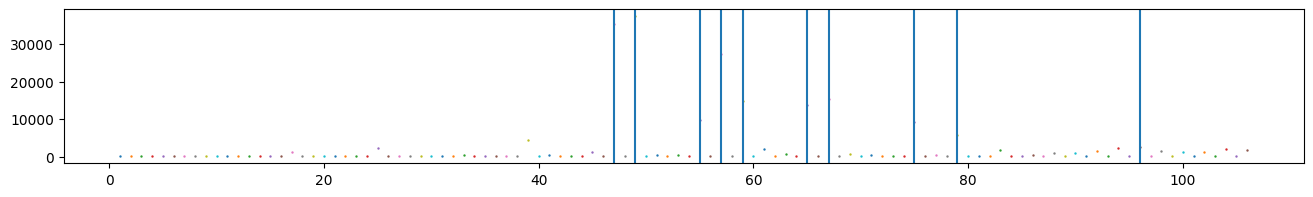

In [66]:
i = 0 # variable to decide which iteration the loop is in
k = 1 # 1 while we apply stain and 0 when we remove strain
count=0
HIGH1 = HIGH
LOW1 = LOW
start_time = datetime.now()
fig = plt.figure(figsize=(16,2))
while True:
    try:
        ser = serial.Serial(PORT)
        ser.flushInput()
        ser_bytes = ser.readline()
        val = float(ser_bytes[0:len(ser_bytes)-2].decode("utf-8"))
        count+=1

        plt.scatter(count, val, s=0.5)
        if i==0 and val< LOW1:
            HIGH1 = val
            LOW1  = val
            HIGH = LOW1
            LOW  = HIGH1
            i+=1
            # print("initial high and low value ", HIGH1, LOW1)
        else:
            if i==0:
                HIGH = LOW1
                LOW  = HIGH1
                i+=1
            if val >= HIGH:
                HIGH = val
                # print("high value changed ", HIGH)
                if k==0:
                    LOW = HIGH
                    LOW1 = LOW
                    HIGH1 = HIGH
            if val <= LOW:
                LOW = val
                # print("low value changed ", LOW)
            MOVEMENT = movement()
            # print("MOVEMENT FOUND : ", MOVEMENT)
            if k==1:
                if MOVEMENT >= GAIN_CHANGE:
                    # print(HIGH1, HIGH, LOW1, LOW)
                    if HIGH-HIGH1 > LOW-LOW1:
                        CYCLE_COUNT+=1
                        plt.axvline(count, 0, 1, label='pyplot vertical line')
                        print(val)
                        # print("New Cycle Detected ", CYCLE_COUNT)
                        k=0
                        LOW = HIGH
                        HIGH1 = HIGH
                        LOW1 = LOW
                    else:
                        HIGH = LOW
            elif k==0:
                if MOVEMENT >= LOSS_CHANGE:
                    # print("MOVEMENT IS MORE THAN LOSS CHANGE")
                    # print(HIGH1, HIGH, LOW1, LOW)
                    if HIGH-HIGH1 < LOW1-LOW:
                        LOW1 = val
                        HIGH1 = val
                        i = 0
                        k = 1

        time_delta = datetime.now() - start_time
        if time_delta.total_seconds() >= 20:
            break
    except:
        print("Keyboard Interrupt")
        break
print("NET CYCLES  ", CYCLE_COUNT)
plt.show()